# 2. Build the cyber-log features

This notebook turns the prepared activity records into one row for each active user-day. A user-day is included when the account has at least one event in any of the five technical channels.

**Inputs:** the saved output from Notebook 1 and the original CERT scenario answer files used in the label section.

**Output:** `features_cyberlog.parquet`, the common technical representation for the baseline and context-augmented configurations. It contains 41 technical features: 29 same-day features and 12 self-history deviations, alongside keys and separately identified outcome columns.

Historical features use preceding active days, with the series shifted so that the current day is excluded from its own reference. Evaluation labels are attached after feature construction and are not detector inputs.

The labels saved here are the as-run labels. Notebook 5c examines the later account-attribution correction. Organisational-context features are added in Notebook 3, not here.

*Documentation copy, 8 November 2026. Notes edited for clarity; code, saved outputs and execution metadata are unchanged. This copy has not been rerun.*


In [1]:
# ============================================================
# 0. Setup
# ============================================================
import os, glob, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED); np.random.seed(SEED)
warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 110

WORK = "/kaggle/working"
AH_START, AH_END = 7, 18     # provisional after-hours boundary (same as NB1)

# auto-locate Notebook 1's output regardless of its mount slug
hits = glob.glob("/kaggle/input/**/logon.parquet", recursive=True)
assert hits, "Notebook 1 output not attached — Add Input -> Your Work -> Notebook 1"
NB1 = os.path.dirname(hits[0])
print("Notebook 1 output found at:", NB1)
print(sorted(os.listdir(NB1)))

Notebook 1 output found at: /kaggle/input/notebooks/thandondhlovu10/1-cert-r6-2-eda-dataset-preparation
['__notebook__.ipynb', '__output__.json', '__results__.html', '__results___files', 'custom.css', 'dataset_summary.csv', 'device.parquet', 'email.parquet', 'figures', 'file.parquet', 'http_daily.parquet', 'imbalance_table.csv', 'insider_http_events.parquet', 'insiders.parquet', 'ldap_monthly.parquet', 'logon.parquet', 'malicious_events.parquet']


In [2]:
# ============================================================
# 0b. Load Notebook 1 outputs
# ============================================================
logon      = pd.read_parquet(f"{NB1}/logon.parquet")
device     = pd.read_parquet(f"{NB1}/device.parquet")
file_      = pd.read_parquet(f"{NB1}/file.parquet")
email      = pd.read_parquet(f"{NB1}/email.parquet")
http_daily = pd.read_parquet(f"{NB1}/http_daily.parquet")
insiders   = pd.read_parquet(f"{NB1}/insiders.parquet")
mal_events = pd.read_parquet(f"{NB1}/malicious_events.parquet")

for df in (logon, device, file_, email):
    df["user"] = df["user"].astype(str)
    df["day"]  = df["date"].dt.normalize()
    df["hour"] = df["date"].dt.hour
    df["ah"]   = ((df["hour"] < AH_START) | (df["hour"] >= AH_END)).astype("int32")
http_daily["user"] = http_daily["user"].astype(str)
http_daily["day"]  = pd.to_datetime(http_daily["day"])

print("loaded:",
      {n: len(d) for n, d in [("logon",logon),("device",device),
                              ("file",file_),("email",email),
                              ("http_daily",http_daily)]})


loaded: {'logon': 3530285, 'device': 1551828, 'file': 2014883, 'email': 10994957, 'http_daily': 1391239}


## 1. Create the active user-day table

Each distinct account and calendar-day pair with at least one event in any channel becomes an observation. Completely inactive user-days are not added.

All channel summaries are left-joined to this common table so that the later configurations use the same observations.


In [3]:
# ============================================================
# 1. Spine
# ============================================================
spine = (pd.concat([logon[["user","day"]], device[["user","day"]],
                    file_[["user","day"]], email[["user","day"]],
                    http_daily[["user","day"]]])
           .drop_duplicates().sort_values(["user","day"])
           .reset_index(drop=True))
spine["dow"]        = spine["day"].dt.dayofweek
spine["is_weekend"] = (spine["dow"] >= 5).astype("int32")
print(f"user-day observations: {len(spine):,} | users: {spine.user.nunique():,}")
print(f"date range: {spine.day.min().date()} -> {spine.day.max().date()}")


user-day observations: 1,394,010 | users: 4,000
date range: 2010-01-02 -> 2011-06-01


## 2. Calculate the daily channel features

The following cells summarise logon, removable-device, file and email activity by user and day. The HTTP summaries have already been prepared by Notebook 1.

The features include activity counts, distinct resources, after-hours activity and selected file or message characteristics. The technical after-hours boundary is shared across users; it is separate from the role-based hours profiles built in Notebook 3.


In [4]:
# ============================================================
# 2a. Logon features
# ============================================================
lg = logon.copy()
lg["act"] = lg["activity"].astype(str).str.lower()
g = lg.groupby(["user","day"], observed=True)

logon_feats = pd.DataFrame({
    "logon_count":      g.apply(lambda d: (d["act"]=="logon").sum()),
    "logoff_count":     g.apply(lambda d: (d["act"]=="logoff").sum()),
    "logon_pcs":        g["pc"].nunique(),
    "logon_afterhours": g.apply(lambda d: d.loc[d["act"]=="logon","ah"].sum()),
    "first_logon_hour": g.apply(lambda d: d.loc[d["act"]=="logon","hour"].min()),
    "last_logoff_hour": g.apply(lambda d: d.loc[d["act"]=="logoff","hour"].max()),
}).reset_index()
print("logon_feats:", logon_feats.shape)


logon_feats: (1394010, 8)


In [5]:
# ============================================================
# 2b. Device features
# ============================================================
dv = device.copy()
dv["act"] = dv["activity"].astype(str).str.lower()
g = dv.groupby(["user","day"], observed=True)
device_feats = pd.DataFrame({
    "device_connects":   g.apply(lambda d: (d["act"]=="connect").sum()),
    "device_pcs":        g["pc"].nunique(),
    "device_afterhours": g.apply(lambda d: d.loc[d["act"]=="connect","ah"].sum()),
}).reset_index()
print("device_feats:", device_feats.shape)


device_feats: (198993, 5)


In [6]:
# ============================================================
# 2c. File features
# ============================================================
fl = file_.copy()
ext = fl["filename"].astype(str).str.lower().str.extract(r"(\.[a-z0-9]+)$", expand=False)
fl["ext_group"] = np.select(
    [ext.isin([".doc",".docx",".pdf",".txt"]),
     ext.isin([".zip",".rar",".7z"]),
     ext.isin([".exe",".dll",".bat",".sh"]),
     ext.isin([".jpg",".jpeg",".png",".bmp",".gif"])],
    ["docs","archives","exec","images"], default="other")

for col in ("to_removable_media","from_removable_media"):
    if col in fl.columns:
        fl[col] = fl[col].astype(str).str.lower().isin(["true","1"]).astype("int32")
    else:
        fl[col] = 0

g = fl.groupby(["user","day"], observed=True)
file_feats = pd.DataFrame({
    "file_events":         g.size(),
    "file_distinct":       g["filename"].nunique(),
    "file_to_removable":   g["to_removable_media"].sum(),
    "file_from_removable": g["from_removable_media"].sum(),
    "file_afterhours":     g["ah"].sum(),
}).reset_index()

ext_counts = (fl.pivot_table(index=["user","day"], columns="ext_group",
                             values="hour", aggfunc="size", fill_value=0)
                .add_prefix("file_").reset_index())
file_feats = file_feats.merge(ext_counts, on=["user","day"], how="left")
print("file_feats:", file_feats.shape)


file_feats: (308647, 11)


In [7]:
# ============================================================
# 2d. Email features
# ============================================================
em = email.copy()
em["act"] = em["activity"].astype(str).str.lower() if "activity" in em.columns else "send"
for c in ("n_to","n_cc","n_bcc","n_to_ext","n_cc_ext","n_bcc_ext",
          "size","attachments"):
    if c not in em.columns:
        em[c] = 0
em["recipients"] = em["n_to"] + em["n_cc"] + em["n_bcc"]
em["external"]   = em["n_to_ext"] + em["n_cc_ext"] + em["n_bcc_ext"]
sent = em[em["act"] == "send"]

g = sent.groupby(["user","day"], observed=True)
email_feats = pd.DataFrame({
    "emails_sent":       g.size(),
    "email_recipients":  g["recipients"].sum(),
    "email_external":    g["external"].sum(),
    "email_attachments": g["attachments"].sum(),
    "email_size":        g["size"].sum(),
    "email_afterhours":  g["ah"].sum(),
}).reset_index()
print("email_feats:", email_feats.shape)
print("email activity values seen:", em['act'].value_counts().to_dict())


email_feats: (1161978, 8)
email activity values seen: {'view': 7162491, 'send': 3832466}


## 3. Assemble the same-day features

Join the channel summaries to the common active user-day table. Missing activity counts become zero, meaning no event of that type was recorded for the day.

Missing first-logon or last-logoff hours use `-1`. This is a missing-value code, not a clock time. The table also retains the calendar features.


In [8]:
# ============================================================
# 3. Merge
# ============================================================
feats = (spine
         .merge(logon_feats,  on=["user","day"], how="left")
         .merge(device_feats, on=["user","day"], how="left")
         .merge(file_feats,   on=["user","day"], how="left")
         .merge(email_feats,  on=["user","day"], how="left")
         .merge(http_daily,   on=["user","day"], how="left"))

hour_cols  = ["first_logon_hour","last_logoff_hour"]
count_cols = [c for c in feats.columns
              if c not in ["user","day","dow"] + hour_cols]
feats[count_cols] = feats[count_cols].fillna(0)
feats[hour_cols]  = feats[hour_cols].fillna(-1)

print("feature matrix:", feats.shape)
feats.head(3)


feature matrix: (1394010, 31)


,user,day,dow,is_weekend,logon_count,logoff_count,logon_pcs,logon_afterhours,first_logon_hour,last_logoff_hour,...,file_images,emails_sent,email_recipients,email_external,email_attachments,email_size,email_afterhours,http_count,http_afterhours,http_distinct_domains
0,AAB0162,2010-01-04,0,0,1,1,1,0,7.0,18,...,0.0,4.0,9.0,1.0,2.0,2471150.0,0.0,95.0,4.0,16.0
1,AAB0162,2010-01-05,1,0,1,1,1,0,7.0,18,...,0.0,5.0,12.0,4.0,0.0,154863.0,0.0,95.0,10.0,14.0
2,AAB0162,2010-01-06,2,0,1,1,1,0,7.0,18,...,0.0,4.0,7.0,0.0,0.0,113254.0,0.0,95.0,10.0,19.0


## 4. Compare activity with each user's earlier days

For twelve behavioural quantities, calculate a z-score against the user's previous 30 active days. `shift(1)` excludes the current observation, and `min_periods=7` requires at least seven preceding active days.

Insufficient history, zero variance or a non-finite result produces a fallback value of zero. That fallback means no usable deviation estimate was available; it does not prove that the current activity equals the historical mean.

The window counts active observations rather than calendar days.


In [9]:
# ============================================================
# 4. Rolling self-baseline z-scores
# ============================================================
Z_COLS = ["logon_count","logon_afterhours","logon_pcs",
          "device_connects","file_events","file_to_removable",
          "emails_sent","email_external","email_size",
          "http_count","http_afterhours","http_distinct_domains"]

feats = feats.sort_values(["user","day"]).reset_index(drop=True)
gb = feats.groupby("user", observed=True)

for c in Z_COLS:
    shifted = gb[c].shift(1)
    m = shifted.groupby(feats["user"], observed=True) \
               .rolling(30, min_periods=7).mean().reset_index(level=0, drop=True)
    s = shifted.groupby(feats["user"], observed=True) \
               .rolling(30, min_periods=7).std().reset_index(level=0, drop=True)
    feats[f"{c}_z"] = ((feats[c] - m) / s.replace(0, np.nan)) \
                        .replace([np.inf,-np.inf], np.nan).fillna(0)

print("added", len(Z_COLS), "z-score features; matrix:", feats.shape)


added 12 z-score features; matrix: (1394010, 43)


## 5. Attach the as-run labels

The original scenario files are read again. The account named in an event row is used when available; otherwise, the designated scenario insider is used. An observed user-day receives `label=1` when at least one answer-file event is attributed to it.

This describes the executed attribution rule, not a guarantee that every attributed event is malicious. Notebook 5c examines the scenario-3 bystander labels created by this rule.

`user_is_insider` separately identifies designated insider accounts for diagnostics. Both outcome fields must remain outside the detector feature list.


In [10]:
# ============================================================
# 5. Labels — v2: attribute events to the ACTUAL account used
# (scenario 3 includes masquerade events under the supervisor's
#  compromised account; label the account used, per the Ch.1
#  definition covering compromised legitimate accounts)
# ============================================================
import csv, re
DATE_RE = re.compile(r"\d{2}/\d{2}/\d{4} \d{2}:\d{2}:\d{2}")
USER_RE = re.compile(r"^[A-Z]{3}\d{4}$")
DATE_FMT = "%m/%d/%Y %H:%M:%S"

hits5 = glob.glob("/kaggle/input/**/answers/**/r6.2-1.csv", recursive=True)
assert hits5, "attach cert-r62-raw (Add Input -> Your Datasets)"
ANS_DIR = os.path.dirname(hits5[0])

file_to_user = dict(zip(insiders["details"].astype(str),
                        insiders["user"].astype(str)))

records = []
for f in sorted(glob.glob(f"{ANS_DIR}/r6.2-*.csv")):
    fname = os.path.basename(f)
    designated = file_to_user.get(fname)
    with open(f, newline="", encoding="utf-8", errors="replace") as fh:
        for row in csv.reader(fh):
            if not row:
                continue
            ts = next((x.strip() for x in row
                       if DATE_RE.fullmatch(x.strip())), None)
            actual = next((x.strip() for x in row
                           if USER_RE.fullmatch(x.strip())), None)
            records.append({"date": ts, "user": actual or designated,
                            "designated_insider": designated,
                            "source_file": fname})

mal = pd.DataFrame(records)
mal["date"] = pd.to_datetime(mal["date"], format=DATE_FMT, errors="coerce")
mal = mal.dropna(subset=["date"])
mal["day"] = mal["date"].dt.normalize()

masq = mal[mal["user"] != mal["designated_insider"]]
print("events executed under a DIFFERENT account than the designated insider:")
print(masq.groupby(["source_file", "user"]).size(), "\n")

mal_days = mal[["user", "day"]].drop_duplicates()
mal_days["label"] = 1

feats = feats.drop(columns=["label"], errors="ignore") \
             .merge(mal_days, on=["user", "day"], how="left")
feats["label"] = feats["label"].fillna(0).astype("int32")
feats["user_is_insider"] = feats["user"].isin(
    set(insiders["user"].astype(str))).astype("int32")

print("malicious user-days:", int(feats.label.sum()),
      "of", len(feats), f"({feats.label.mean()*100:.4f}%)")
print("\nmalicious user-days per account:")
print(feats[feats.label == 1].groupby("user").agg(
      days=("day", "size"), first=("day", "min"), last=("day", "max")))
print("\nmalicious user-days by month:")
print(feats[feats.label == 1]
      .assign(month=lambda d: d["day"].dt.to_period("M"))
      .groupby("month").size())

missing = mal_days.merge(spine[["user", "day"]], on=["user", "day"],
                         how="left", indicator=True)
n_miss = (missing["_merge"] == "left_only").sum()
print(f"\nanswer-key user-days not found in spine: {n_miss} (expect 0)")

events executed under a DIFFERENT account than the designated insider:
source_file  user   
r6.2-3.csv   CAC1777    3
             DMC1766    2
             DNS1758    6
             DNS1768    1
             GAH1760    1
             GCH0735    1
             GFJ2582    2
             GJS0494    1
             HIS1706    8
             JDS0516    1
             JGN1767    1
             KAC1774    2
             KMB1761    3
             KSM1772    1
             LEB1764    1
             MAB1775    2
             NHH1704    2
             QAH0048    1
             SDW0370    1
             TWK1773    2
             VAB1526    1
             WSA1765    2
             YKW1763    2
             ZAP1762    3
dtype: int64 

malicious user-days: 78 of 1394010 (0.0056%)

malicious user-days per account:
         days      first       last
user                               
ACM2278     3 2010-08-18 2010-08-24
CAC1777     2 2010-08-16 2010-08-17
CDE1846     9 2011-02-21 2011-04-25
CMP2946   

## 6. Check the assembled table

The assertions check for missing and non-finite values. The correlation output identifies strongly related feature pairs and saves a correlation figure.

The printed phrase "candidates to prune" is a diagnostic suggestion in the original code. This section does not remove those features or change the retained 41-feature representation.


feature pairs with |corr| > 0.95 (candidates to prune in NB4):
   ('logoff_count', 'logon_pcs', np.float64(0.981))
   ('file_events', 'file_from_removable', np.float64(0.955))
   ('file_events', 'file_docs', np.float64(0.981))
   ('email_attachments', 'email_size', np.float64(0.952))


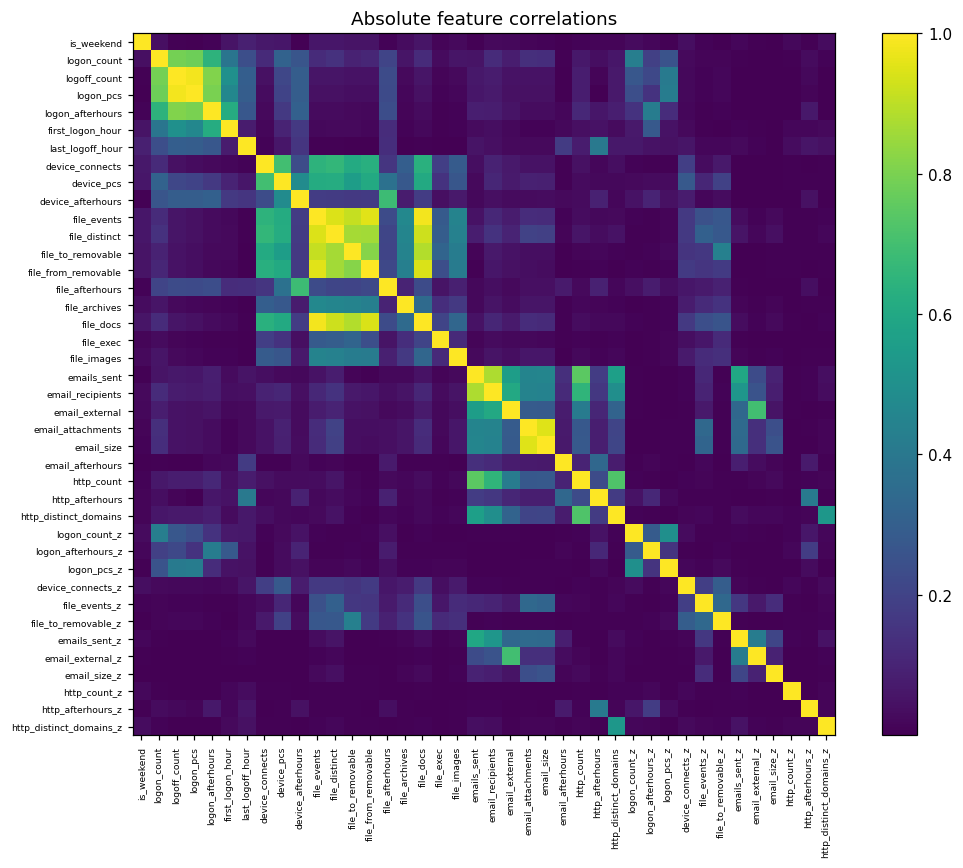

In [11]:
# ============================================================
# 6. Sanity checks
# ============================================================
assert feats.isna().sum().sum() == 0, "NaNs remain!"
assert np.isfinite(feats.select_dtypes("number")).all().all(), "non-finite values!"

num = feats.drop(columns=["user","day","label","user_is_insider","dow"]) \
           .select_dtypes("number")
corr = num.corr().abs()
high = [(a, b, round(corr.loc[a,b],3))
        for i, a in enumerate(corr.columns)
        for b in corr.columns[i+1:] if corr.loc[a,b] > 0.95]
print("feature pairs with |corr| > 0.95 (candidates to prune in NB4):")
for t in high: print("  ", t)

fig, ax = plt.subplots(figsize=(10,8))
im = ax.imshow(corr, cmap="viridis")
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=90, fontsize=6)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns, fontsize=6)
plt.colorbar(im); plt.title("Absolute feature correlations")
plt.tight_layout(); plt.savefig(f"{WORK}/fig_feature_corr.png", dpi=300)
plt.show()


## 7. Save the common technical table

Save `features_cyberlog.parquet` for Notebooks 3, 4 and 5. Notebook 3 removes the outcome columns when it loads the table; the modelling notebooks recover them separately for their checks, selection and evaluation.

Keep the saved version together with its input versions. The final diagnostic cell prints the available software-version information.


In [12]:
# ============================================================
# 7. Save
# ============================================================
out = f"{WORK}/features_cyberlog.parquet"
feats.to_parquet(out, index=False)
print(f"saved {out}: {feats.shape[0]:,} rows x {feats.shape[1]} cols "
      f"({os.path.getsize(out)/1e6:,.1f} MB)")
print("\ncolumns:")
print(list(feats.columns))


saved /kaggle/working/features_cyberlog.parquet: 1,394,010 rows x 45 cols (69.0 MB)

columns:
['user', 'day', 'dow', 'is_weekend', 'logon_count', 'logoff_count', 'logon_pcs', 'logon_afterhours', 'first_logon_hour', 'last_logoff_hour', 'device_connects', 'device_pcs', 'device_afterhours', 'file_events', 'file_distinct', 'file_to_removable', 'file_from_removable', 'file_afterhours', 'file_archives', 'file_docs', 'file_exec', 'file_images', 'emails_sent', 'email_recipients', 'email_external', 'email_attachments', 'email_size', 'email_afterhours', 'http_count', 'http_afterhours', 'http_distinct_domains', 'logon_count_z', 'logon_afterhours_z', 'logon_pcs_z', 'device_connects_z', 'file_events_z', 'file_to_removable_z', 'emails_sent_z', 'email_external_z', 'email_size_z', 'http_count_z', 'http_afterhours_z', 'http_distinct_domains_z', 'label', 'user_is_insider']


In [13]:
try:
    print("pd:", pd.__version__)
except NameError:
    print("pd NOT defined — setup cell not run yet")

try:
    print("NB1:", NB1)
except NameError:
    print("NB1 NOT defined — setup cell not run yet")

pd: 2.3.3
NB1: /kaggle/input/notebooks/thandondhlovu10/1-cert-r6-2-eda-dataset-preparation
